# AI-aided pair

In [1]:
from data_loading import load_all, multi_value_datasets, best_worst_configs
import plotss as P
import diagnostics as d
import embedding as E

df_windows, df_series, df_config = load_all()

df_forecasts = d.build_forecast_table("output/results/TiRex2", cache_path="forecasts.parquet")
df_analysis  = d.merge_with_windows(df_windows, df_forecasts)

windows with forecast diagnostics: 100.0% of 109607


## Get the big picture across all datasets

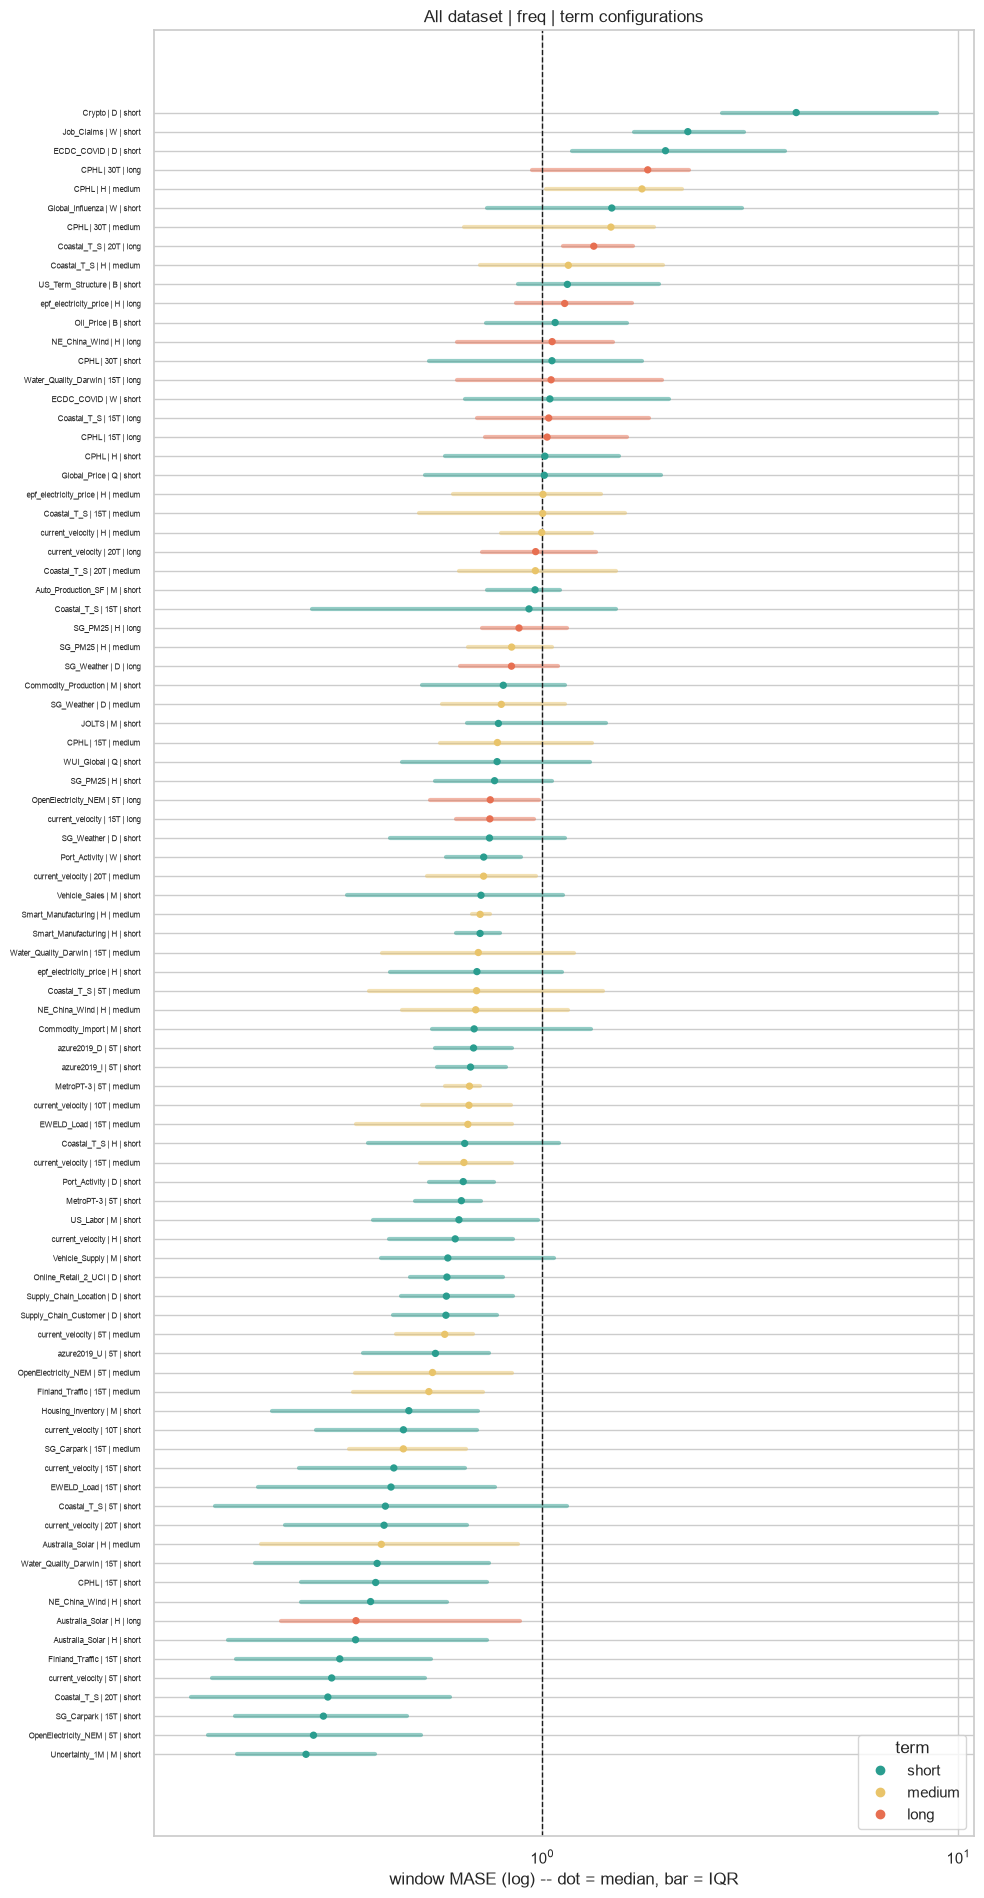

In [2]:
P.plot_config_overview(df_config)

The bar is MASE = 1 and is meant to be a simple naive benchmark that shows how well the model predicts different datasets. For datasets such as Crypto|D|short and Job_Claims|W|short the model performs worse than the baseline. But on the other side, the models is outperforming the baseline for, mostly, short term dataset configurations. Overall, the plot demonstates that the model is struggling more with the long and medium term.

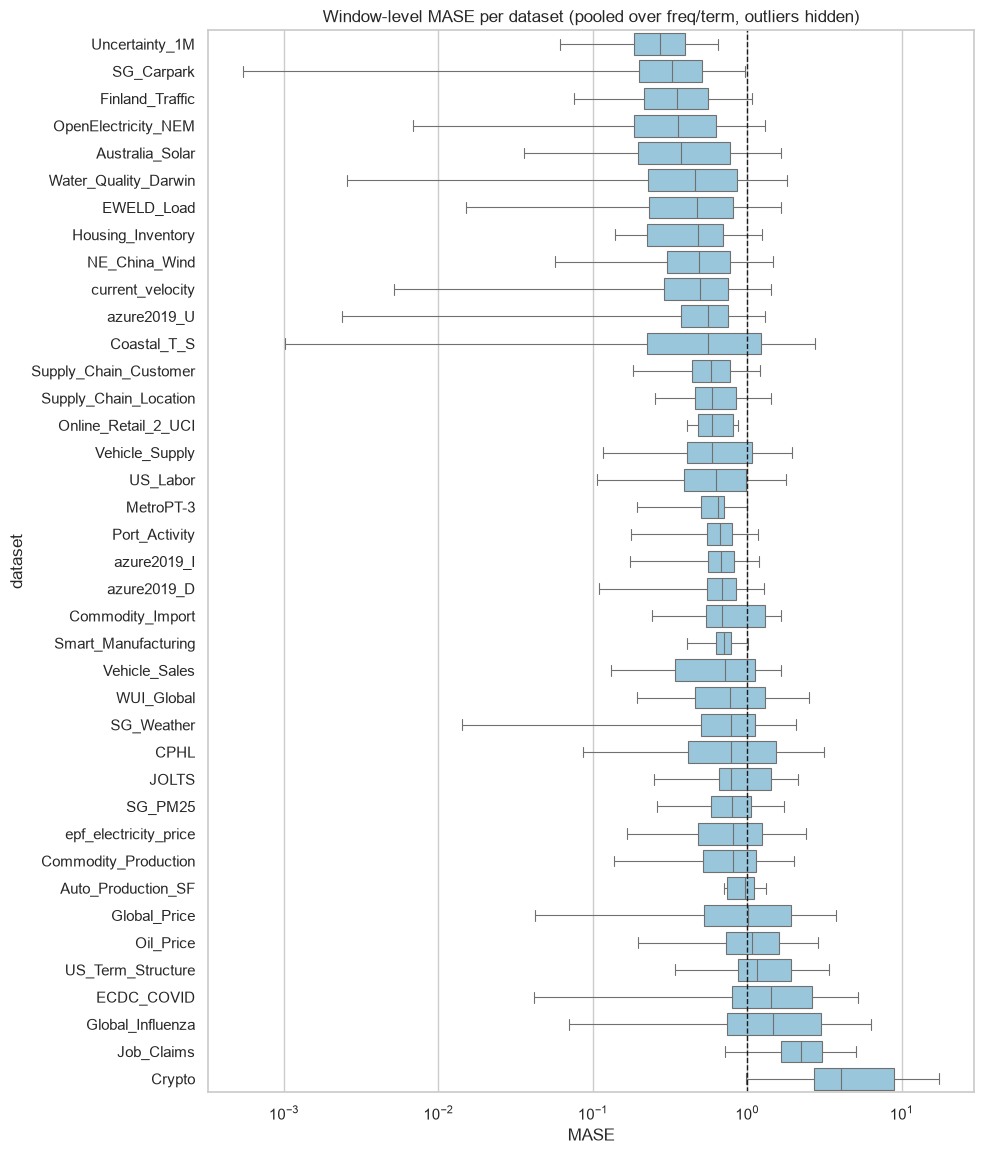

In [3]:
P.plot_mase_by_dataset(df_windows)

High-noise financial datasets stay near the bottom with meadians of near 1.0 or above, proving they are hard to predict across all frequencies and terms. Sensor, physical and traffic datasets set near the top, showing strong predictability across setups. Datasets such as SG_carparl and Coastal_T_S with wide boxes and long whiskers show that performance depends heavilty on the specific term or frequency chosen. 

No features available, left out of the profile: ['Crypto']


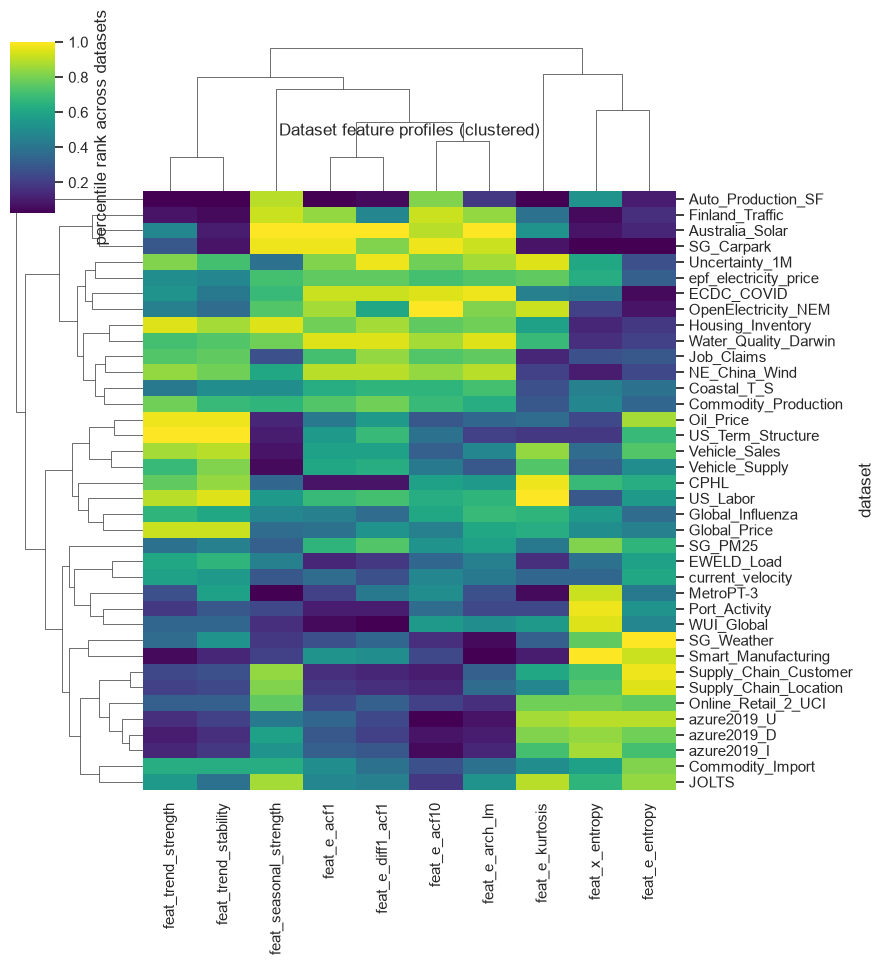

In [4]:
P.plot_feature_profile(df_config)

<!-- In the figures above, the model underperforms for Job_Claims, Global_Influenza, ECDC_Covid -->

In [5]:
multi_value_datasets(df_config, "freq")

['CPHL', 'Coastal_T_S', 'ECDC_COVID', 'Port_Activity', 'current_velocity']

In [6]:
multi_value_datasets(df_config, "term")

['Australia_Solar',
 'CPHL',
 'Coastal_T_S',
 'EWELD_Load',
 'Finland_Traffic',
 'MetroPT-3',
 'NE_China_Wind',
 'OpenElectricity_NEM',
 'SG_Carpark',
 'SG_PM25',
 'SG_Weather',
 'Smart_Manufacturing',
 'Water_Quality_Darwin',
 'current_velocity',
 'epf_electricity_price']

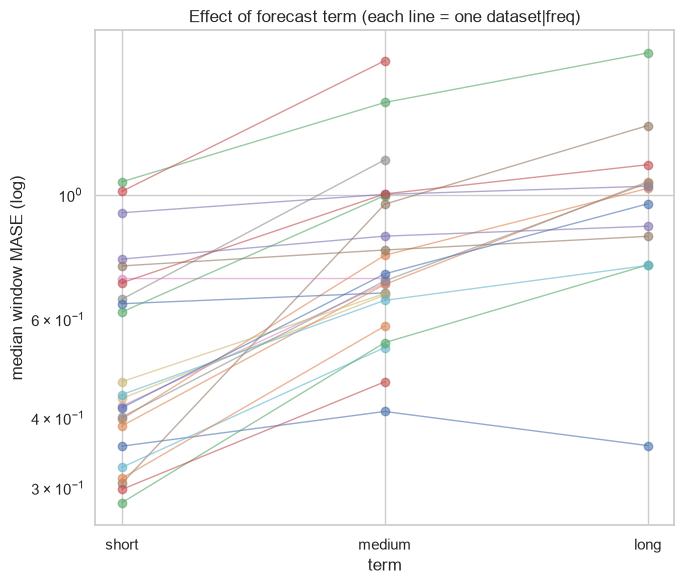

In [7]:
P.plot_term_comparison(df_config)

Evaluating model performance across forecast terms reveals consistent horizon degradation across nearly all dataset configurations. While TiRex2 demonstrates strong baseline superiority in short-term, performance systematically decays toward or past the naive baseline  as the horizon extends to medium and long terms. 

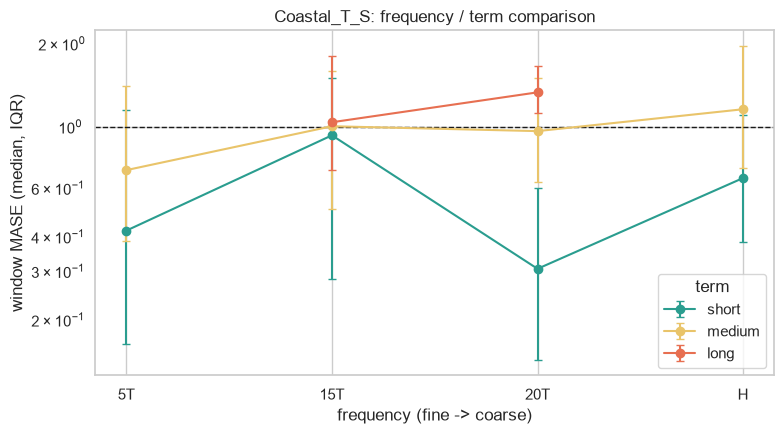

In [8]:
P.plot_freq_comparison(df_config, "Coastal_T_S")

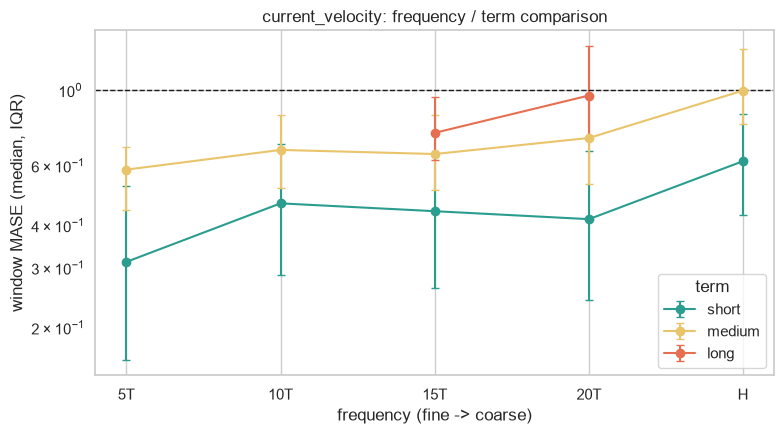

In [9]:
P.plot_freq_comparison(df_config, "current_velocity")

Comparing frequency sensitivity between Coastal_T_S and current_velocity highlights two distinct behavioral modes in the data. While Coastal_T_S exhibits non-monotonic aliasing effects, current_velocity demonstrates monotonic error growth as sampling frequency coarsens. For current_velocity, fine 5-minute sampling (5T) yields the best accuracy ($\text{MASE} \approx 0.30$), while hourly aggregation (H) degrades medium-term predictions to the naive baseline threshold ($\text{MASE} = 1.0$).

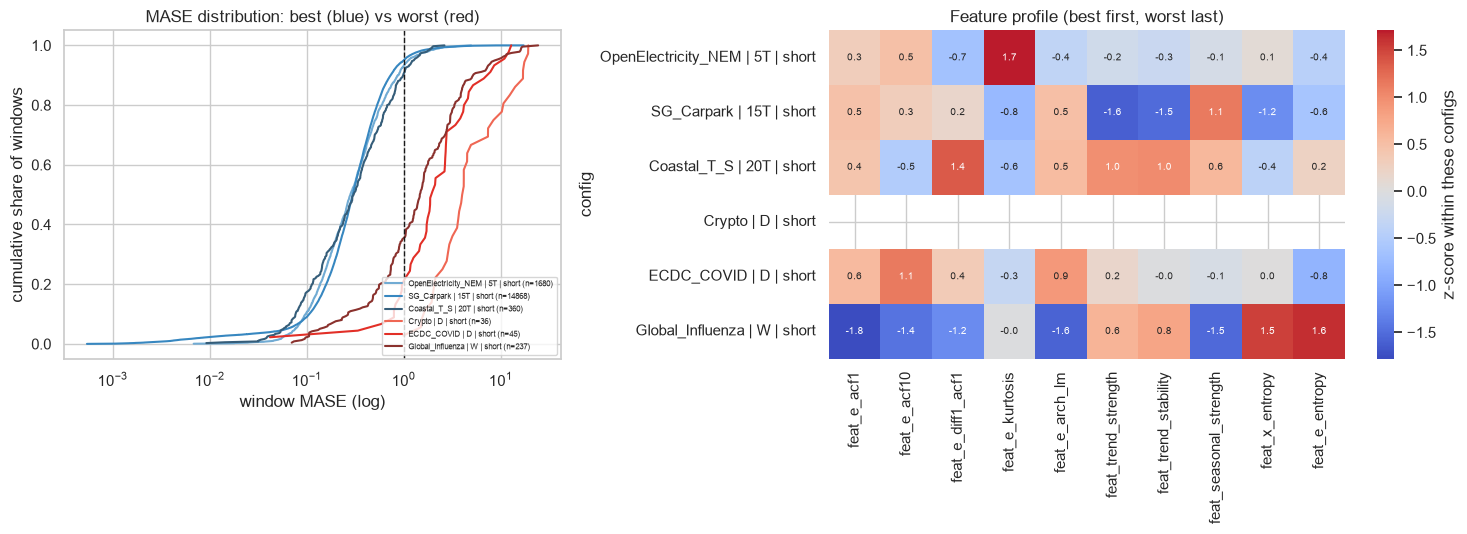

In [10]:
best, worst = best_worst_configs(df_config, k=3, min_windows=30)
P.plot_best_worst(df_windows, best, worst)

In this plot, the top 3 best and worst performing dataset setups are compared. In the left plot, the blue curves (best), sits mostly to the left, achieving $\text{MASE}<1.0$. The red curves (worst) sit mostly to the right of 1.0. For Crypto|D|short, $100\%$ of windows exceed the naive baseline. There is also a difference in the steepness of the slopes: the blue curves are steep, meaning the model's performance is highly consistent across windows, whereas the red curves have wieder, shallower slopes, indicating high variance between windows (some windows might do good, while others have massive error spikes).

Z-score feature profile reveals why the model might fail for some dataset configurations. The model might rely on trend strength in combination with seasonal strength to outperform the baseline. In addition, entropy could also be an important factor in the performance of the model. By taking into account the different combinations of these factors, we can see why the curves behave the way they do.

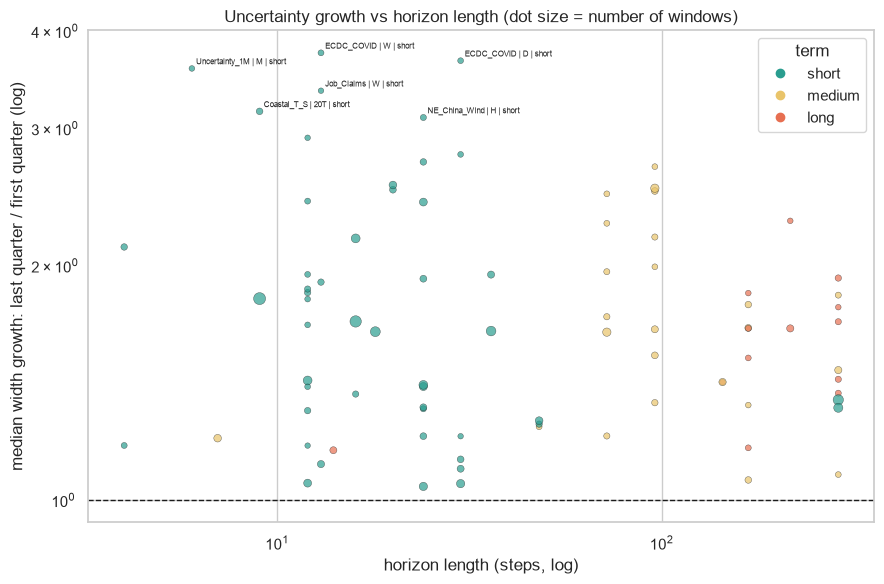

In [11]:
P.plot_width_growth_overview(df_analysis)

An overview of uncertainty growth across all configurations confirms universal interval expansion ($\text{width growth} > 1.0$), demonstrating that TiRex2 reliably scales prediction bounds as temporal horizons extend. The sharpest relative growth ratios ($3.0\times–4.0\times$) occur in short-horizon, high-volatility configurations (ECDC_COVID, Job_Claims), where initial confidence is high but rapidly decays. Conversely, long-horizon configurations exhibit more conservative, steady growth ratios ($1.2\times–2.0\times$) due to wider baseline initial intervals.

A key finding in uncertainty evaluation is the contrast between baseline error and relative uncertainty growth. While Uncertainty_1M achieves the lowest overall median MASE in the benchmark ($\text{MASE} < 0.3$), it exhibits a high relative uncertainty growth ratio ($\sim 3.6\times$). This paradox is driven by a tiny initial denominator: because initial step confidence is exceptionally high (narrow intervals), standard horizon variance accumulation produces a large percentage increase while absolute error remains minimal.

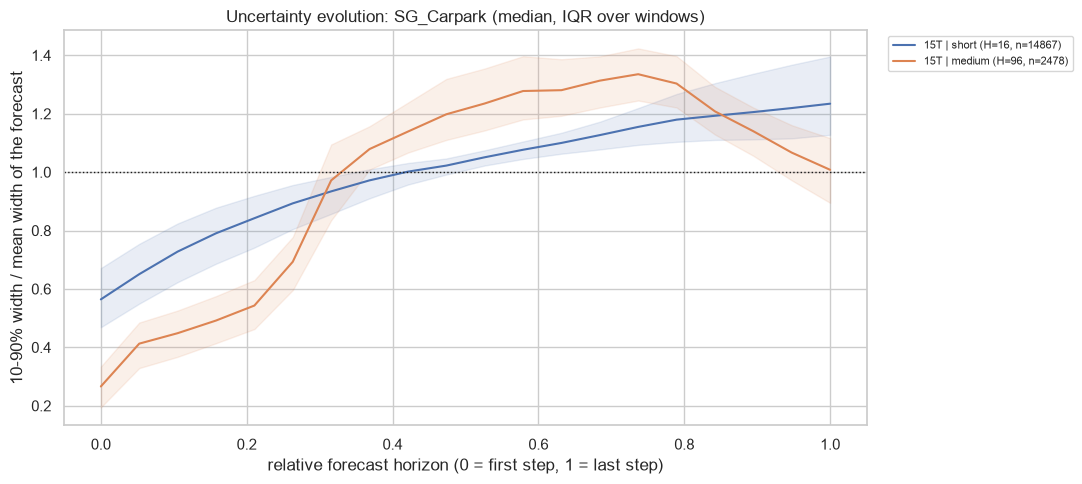

In [12]:
P.plot_uncertainty_evolution(df_analysis, "SG_Carpark")

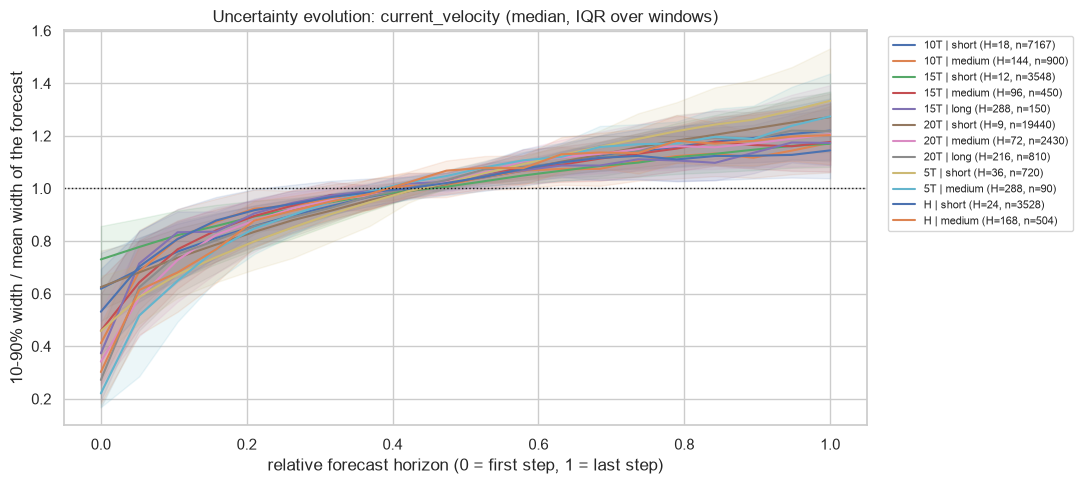

In [13]:
P.plot_uncertainty_evolution(df_analysis, "current_velocity")

To understand the mechanisms behind the macro uncertainty trends, we examine two contrasting case studies:  current_velocity: Across all frequencies and terms, relative interval width grows continuously with the horizon.  SG_Carpark: In the medium term ($15T, H=96$), uncertainty expands mid-horizon but contracts back to ~1.0 at step 1.0. Because $96 \times 15\text{ min} = 24\text{ hours}$, TiRex2 might leverage learned daily occupancy cycles to reduce uncertainty at complete periodic boundaries, something that is  missing in shorter, non-periodic horizons ($H=16$). This might be something interesting to see in Phase II.

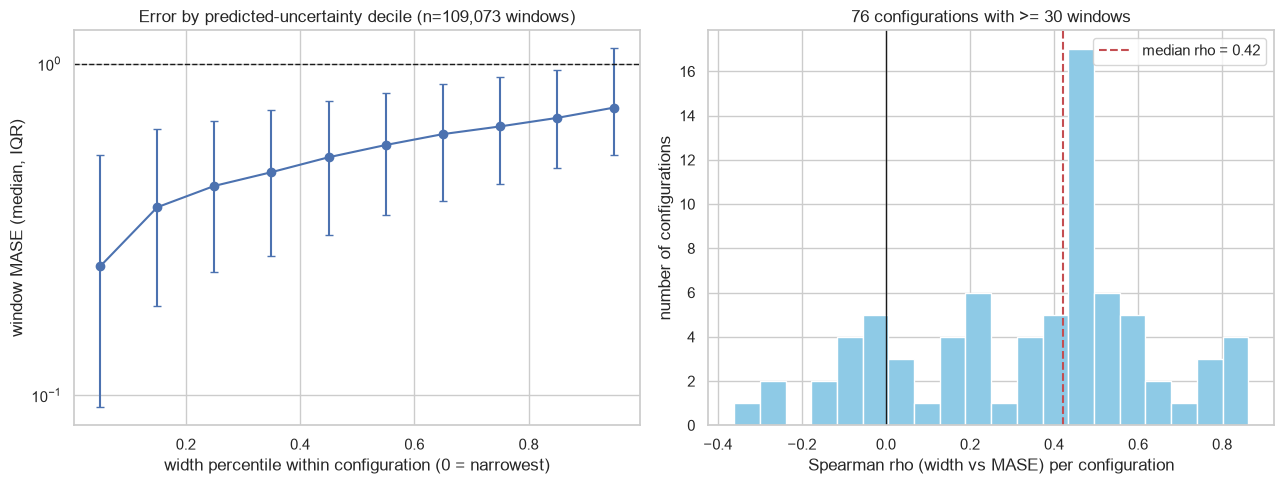

In [14]:
P.plot_width_vs_error(df_analysis)

Evaluating model self-awareness via predicted interval widths confirms interval width is informative about error. Across 109,073 windows, actual forecast error scales monotonically with predicted uncertainty deciles: windows in the narrowest 10th percentile achieve much lower MASE(~0.3), whereas windows in the widest 10th percentile yield MASE ~0.8. Wider confidence bounds directly correlate with higher actual error. 


Evaluating Spearman rank correlation ($\rho$) per configuration confirms that uncertainty calibration is structurally consistent, with a median correlation of $\rho = 0.42$ across 76 evaluated configurations. The sharp peak around $\rho \approx 0.45$ demonstrates that for most datasets, predicted interval widths reliably track actual error ranks. However, the minority of configurations exhibiting negative correlation ($\rho < 0$) pinpoint specific failure modes where sudden structural breaks cause overconfident prediction intervals

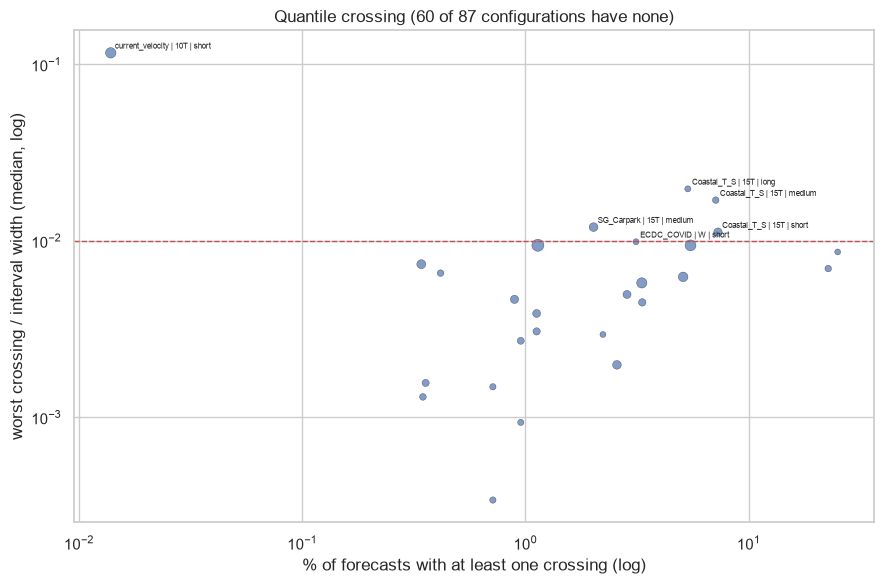

In [15]:
P.plot_crossing_overview(df_analysis)

Out of all 87 configurations, only 27 have quantile crossing. Of the 27, the vast majority is under the threshold for non-trivial violations (the red line). The configurations above belong mostly to a small subset of high-variance sensor series, Coastal_T_S dataset and current_velocity. Overall, the model has a good structural integrity.

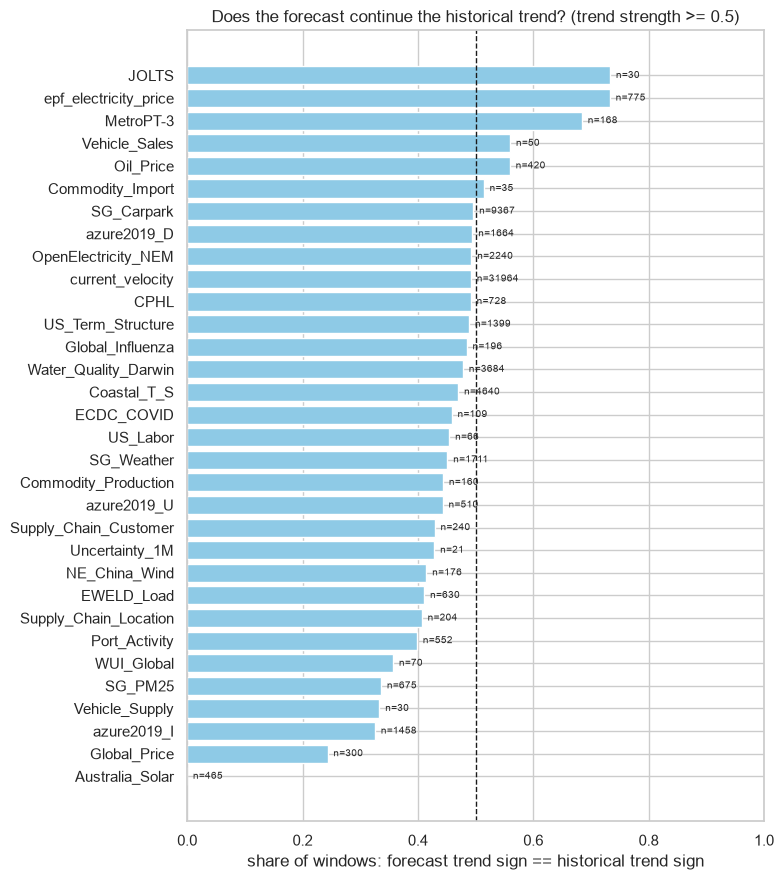

In [16]:
P.plot_drift_vs_history_trend(df_analysis)

Based on this plot, TiRex2 has a dominant mean-reversive prior, it predicts the opposite of the past trend. Most of the datasets are to the left and Australia_Solar is close to 0. It would be interesting to see why the model does this in Phase II. 

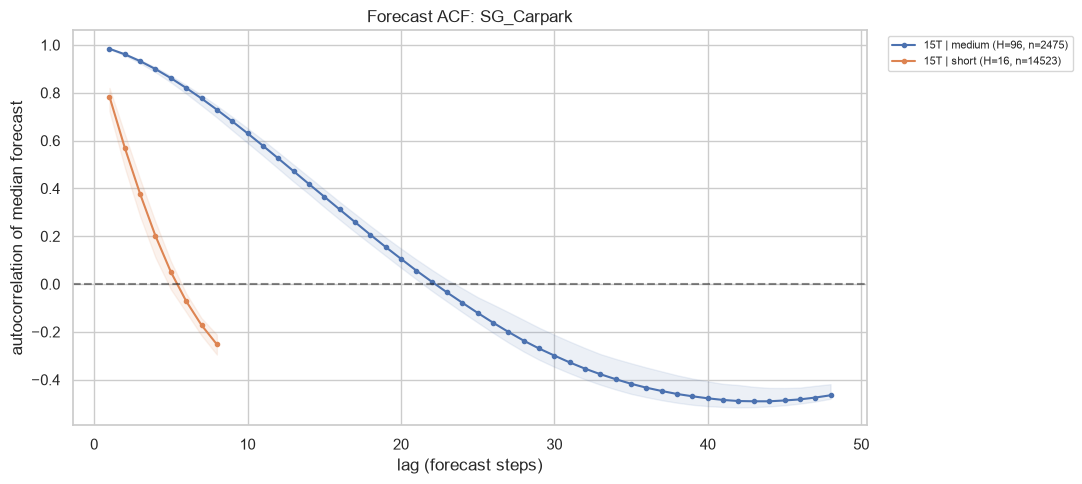

In [17]:
acf_df = d.acf_profiles("output/results/TiRex2", "SG_Carpark")
P.plot_acf_comparison(acf_df, "SG_Carpark")

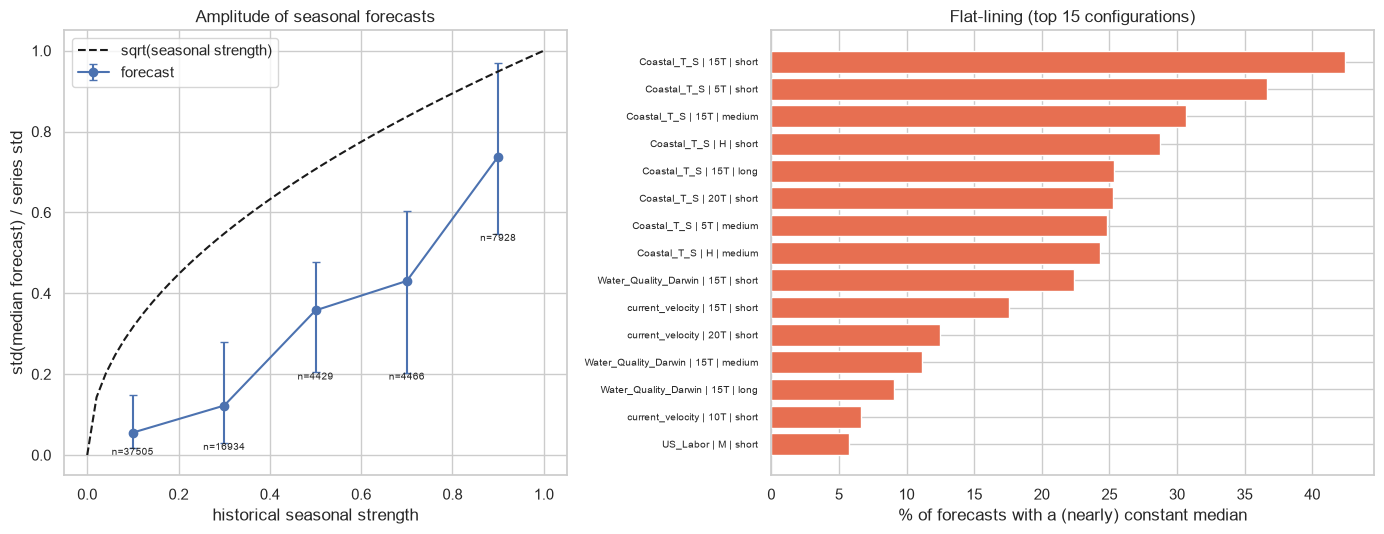

In [18]:
P.plot_seasonal_damping(df_analysis)

In [19]:
# df_analysis.groupby("is_flat")[["MASE","width_growth"]].median()

In [20]:
# df_analysis.query("dataset=='Australia_Solar'")[["feat_linearity","trend_change_std"]].describe()

On the left: The Theoretical Reference(black dashed line) represents the expected amplitude if the model fully reproduced the historical seasonal component. The blue curve sit consistently below the reference line acorss all bins. For weak to moderate seaonality(0.0-0.4) TiRex2 dampens the variance, forecast amplitude dropping near 0. For strong seasonality (0.8-1.0), TiRex2 can recover only ~$75\%$ of the expected std, even though the historical seasonality is extremely high. This could mean that TiRex2 has a build-in variance suppression bias. It systematically smooths out seasonal peaks and troughts to minimize square errors rather than outputting full-amplitute cycles.

On the right: Flat-lining is the percentage of evaluation windows where the median trajectory degenerates into a nearly constant horizontal line. Majority of Coastal_T_S configurations have a high procentage of flat median forecasts. 9 out of 15 configurations are short terms, which might indicate that when TiRex2 is dealing with high short-term noise or very fine sampling resolutions,the default safety mechanism is to output a constant level(flat line) rather than risk dynamic predictions. 

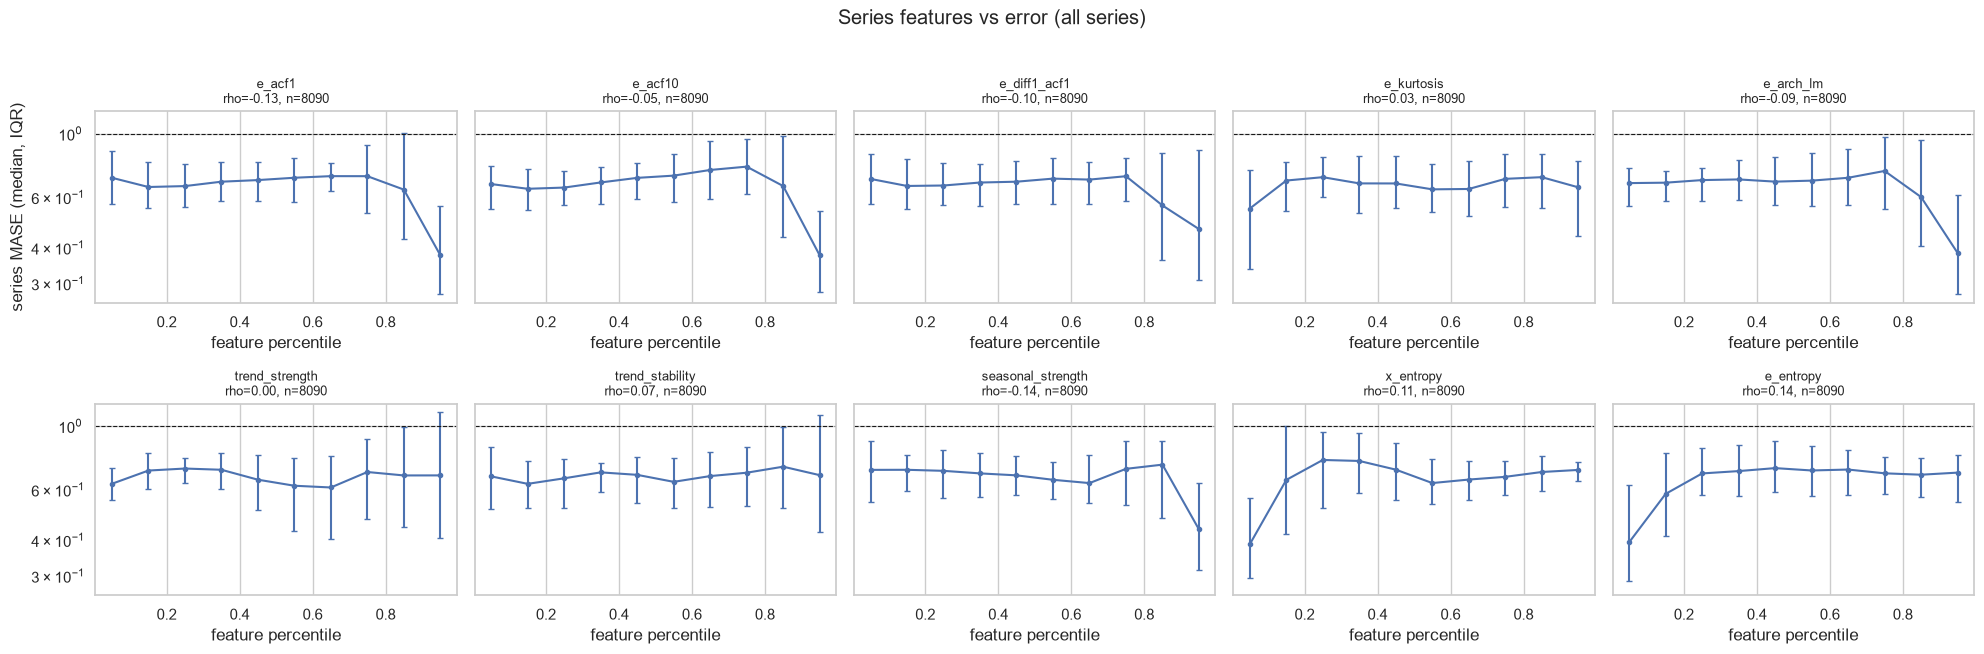

In [21]:
P.plot_feature_error_relationship(df_series)

Evaluating feature-error relationships across all 8,090 individual series confirms that model performance is governed by non-linear feature thresholds rather than smooth linear trends. High lag-1 autocorrelation (e_acf1, $\rho = -0.13$) and strong seasonal periodicity (seasonal_strength, $\rho = -0.14$) serve as primary prerequisites for high precision, driving median error down from $\text{MASE} \approx 0.70$ to $\sim 0.38–0.45$ in the top 20th feature percentiles. Conversely, structural entropy (e_entropy, $\rho = +0.14$) presents a strict performance wall: series exceeding the 20th entropy percentile suffer immediate error elevation. Notably, pure linear trend strength (trend_strength, $\rho = 0.00$) exhibits zero correlation with forecast accuracy, reinforcing the model's reliance on periodic structure over linear momentum.

In [22]:
# RESULTS_DIR = "output/results/TiRex2"
# q, levels = d.load_config(RESULTS_DIR, "Crypto", "D", "short")

# picks = d.pick_windows_by_error(df_analysis, "Crypto | D | short")
# for _, r in picks.iterrows():
#     fig = P.plot_forecast_fan(q, levels, int(r.series_idx), int(r.window_idx), int(r.variate_idx),
#                               title=f"Crypto D short, MASE={r.MASE:.2f} ({r.MASE_quantile:.0%} quantile)")
#     display(fig)

Rows dropped (missing features): {'SG_Carpark': 8, 'Crypto': 4}


c:\Users\Lenovo\Documents\JKU\Aiviz\aiviz\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\Lenovo\Documents\JKU\Aiviz\aiviz\.venv\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


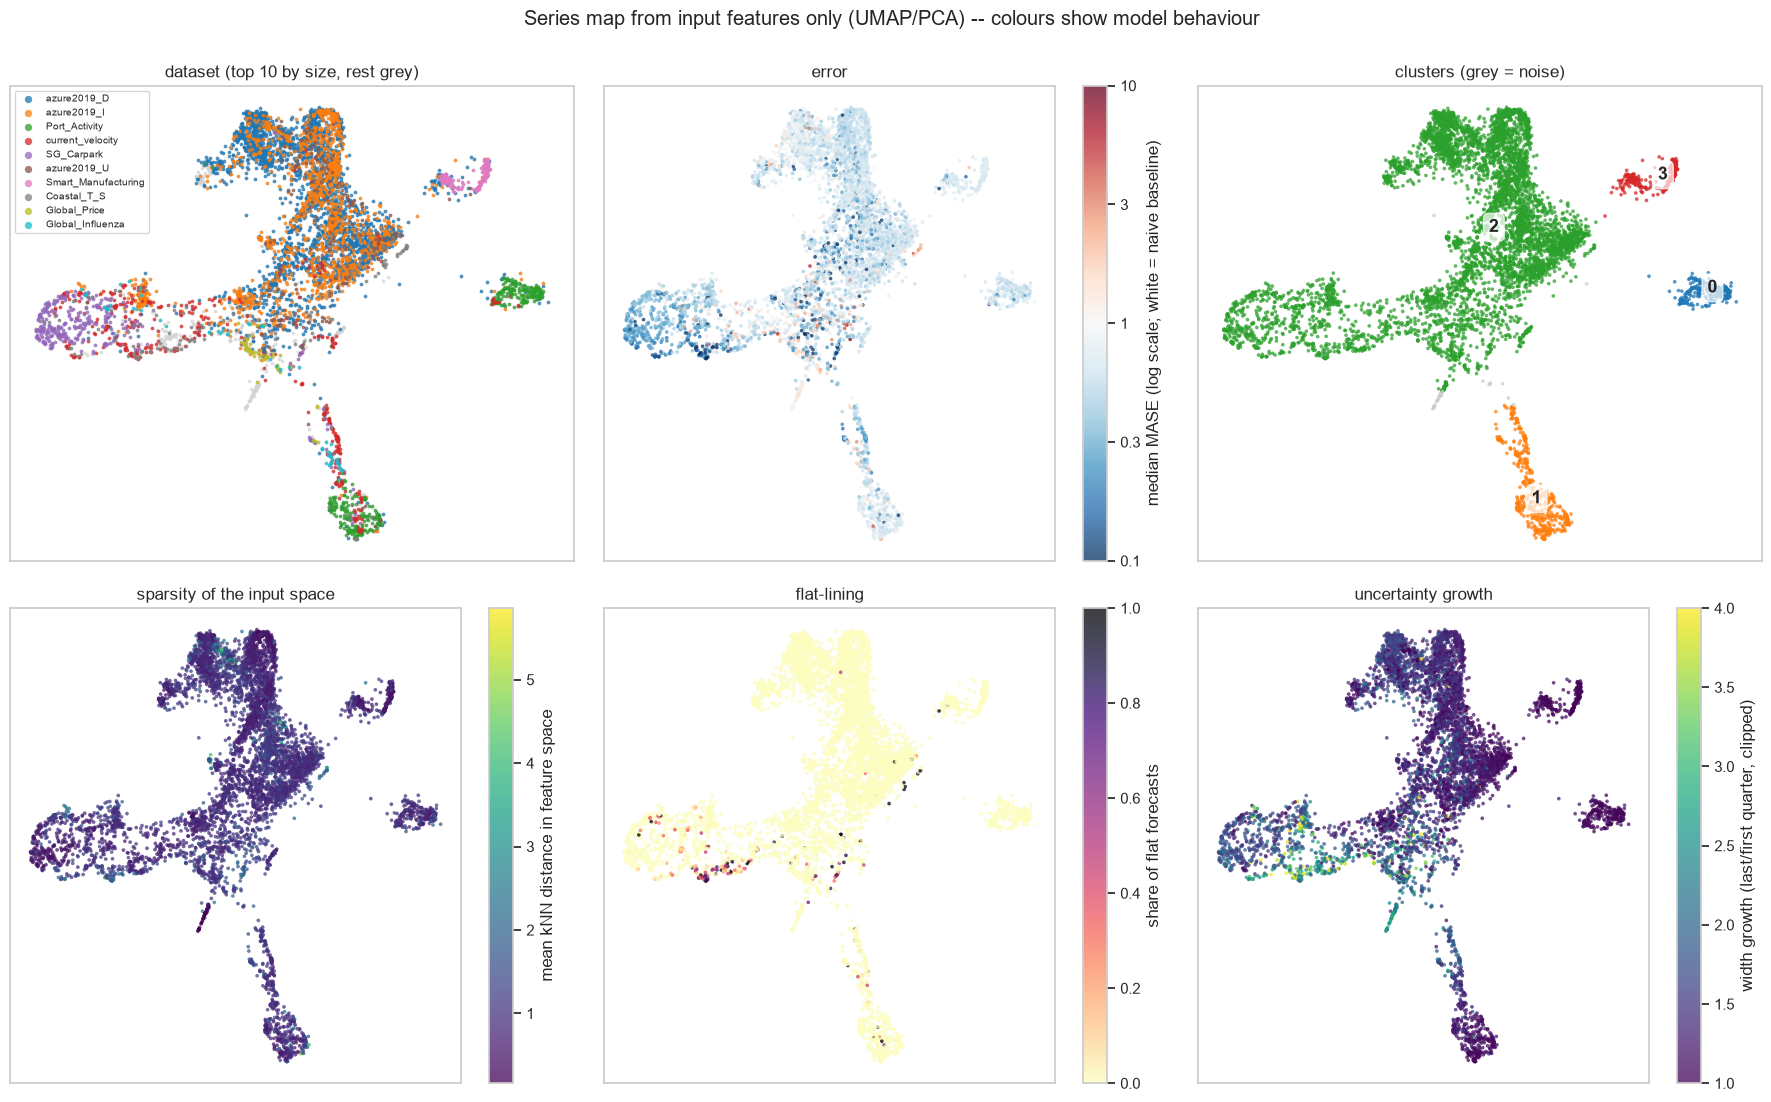

In [23]:
import importlib
importlib.reload(E)

tbl = E.build_series_table(df_analysis, term="short")   # one row per series-variate
emb = E.embed(tbl, method="umap", n_neighbors=30, min_dist=0.1, max_per_dataset=500)
emb = E.cluster_embedding(emb, min_cluster_size=60)     # HDBSCAN on the 2-D map, -1 = noise

P.plot_embedding_panels(emb)                            # 6 views of the same map

The error is pale blue almost everywhere. Cluster medians are nearly identical(0.65 for clusters 0, 1 , 2 and 0.7 for cluster 3). Clusters differ in spread, not typical error. These input features poorly separate typical median error across dense cluters, but strongly localize forecasting behaviours and isolate high-error outliers.

In the lower middle part of the left arm has the darkest blue points(MASE below 0.2), a streak of flat-lining and the highest width growth. The region coresponds mostly to current_velocity, Coastal_T_S. These 2 datasets are the same ones that topped the flat-lining. 

Cluster 2 holds the majority of the series (n=5688) and the only group above naive is the noise group (-1, n=31). Its median MASE is about 1.1 and it contains atypical series that didn't fit in other regions.

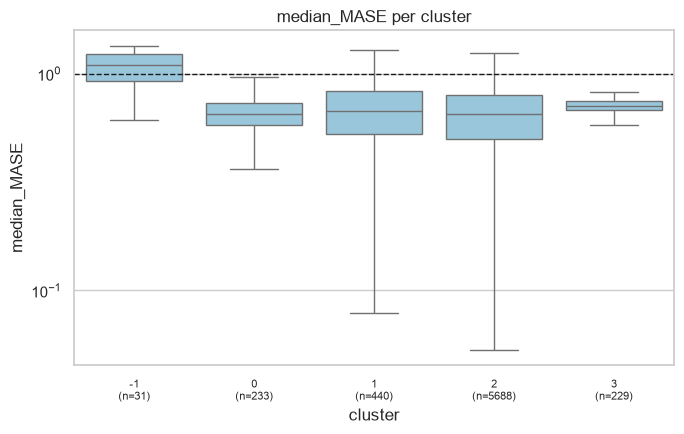

In [24]:
prof = E.cluster_profile(emb)                           # table: size, composition, feature z-scores, outcomes
P.plot_cluster_profile(prof)
P.plot_cluster_distributions(emb, "median_MASE")

In [25]:
# E.dataset_purity(emb)

In [26]:
# emb = E.cluster_embedding(emb, min_cluster_size=30, selection="leaf")   # finer clusters
# emb = E.dataset_purity(emb); print(emb.purity.describe())

# print(emb[emb.cluster == -1].dataset.value_counts())                    # who is the noise group?
# P.plot_distinguishing(E.distinguishing_features(emb, -1), -1)           # what sets it apart

# emb["flat_group"] = (emb.flat_share > 0.3).astype(int)                  # define the left-arm region by behavior
# P.plot_distinguishing(E.distinguishing_features(emb.assign(cluster=emb.flat_group), 1), "flat-lining series")

# prof = E.cluster_profile(emb); P.plot_cluster_profile(prof)
# E.window_behavior_by_cluster(df_analysis, emb)

In [27]:
c = -1                                                   # worst-error cluster from prof
dist = E.distinguishing_features(emb, c)                # AUC of each feature/outcome, cluster vs rest
P.plot_distinguishing(dist, c)

sub = E.subcluster(emb, c, method="umap", min_cluster_size=25)   # sub-clusters inside it
wb  = E.window_behavior_by_cluster(df_analysis, emb)    # per cluster: flat share, crossing, width growth,
                                                        # and rho between interval width and error

c:\Users\Lenovo\Documents\JKU\Aiviz\aiviz\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\Lenovo\Documents\JKU\Aiviz\aiviz\.venv\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [28]:
P.plot_embedding_interactive(emb)    # as the last line of a cell

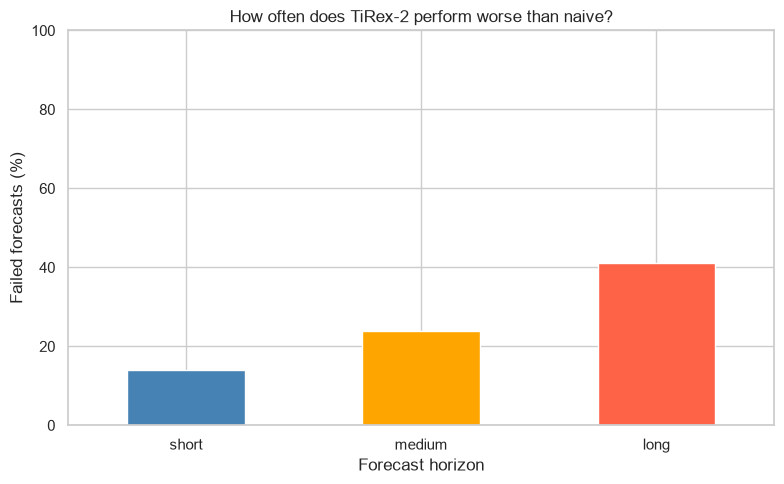

term
short     13.974360
medium    23.958423
long      40.975610
Name: failed, dtype: float64

In [29]:
import plots2 as p2
p2.plot_failure_rate(df_analysis)

c:\Users\Lenovo\Documents\JKU\Aiviz\aiviz\team_red\plots2.py:46: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  heatmap_data = data.pivot_table(


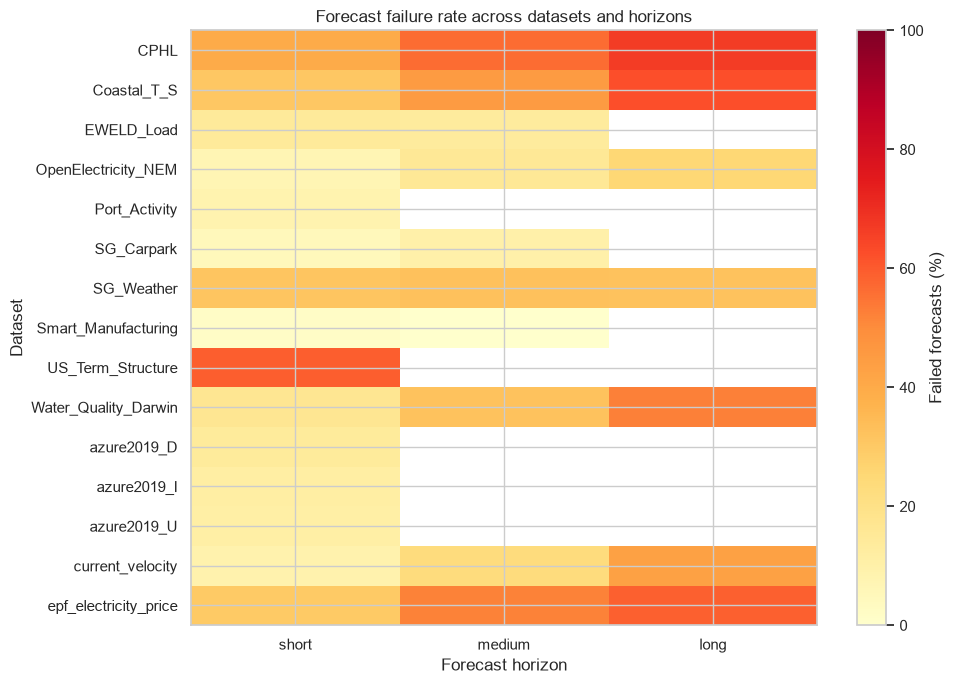

term,short,medium,long
dataset,,,
CPHL,39.527027,56.603774,66.666667
Coastal_T_S,30.602477,45.248538,62.222222
EWELD_Load,14.285714,13.571429,NaN
OpenElectricity_NEM,6.845238,15.476190,25.000000
Port_Activity,8.554293,NaN,NaN
SG_Carpark,5.024213,9.967716,NaN
SG_Weather,31.284153,32.772436,32.371795
Smart_Manufacturing,1.932773,0.000000,NaN
US_Term_Structure,59.142857,NaN,NaN


In [30]:
p2.plot_failure_heatmap(df_analysis)  #top_n=x

c:\Users\Lenovo\Documents\JKU\Aiviz\aiviz\team_red\plots2.py:46: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  heatmap_data = data.pivot_table(


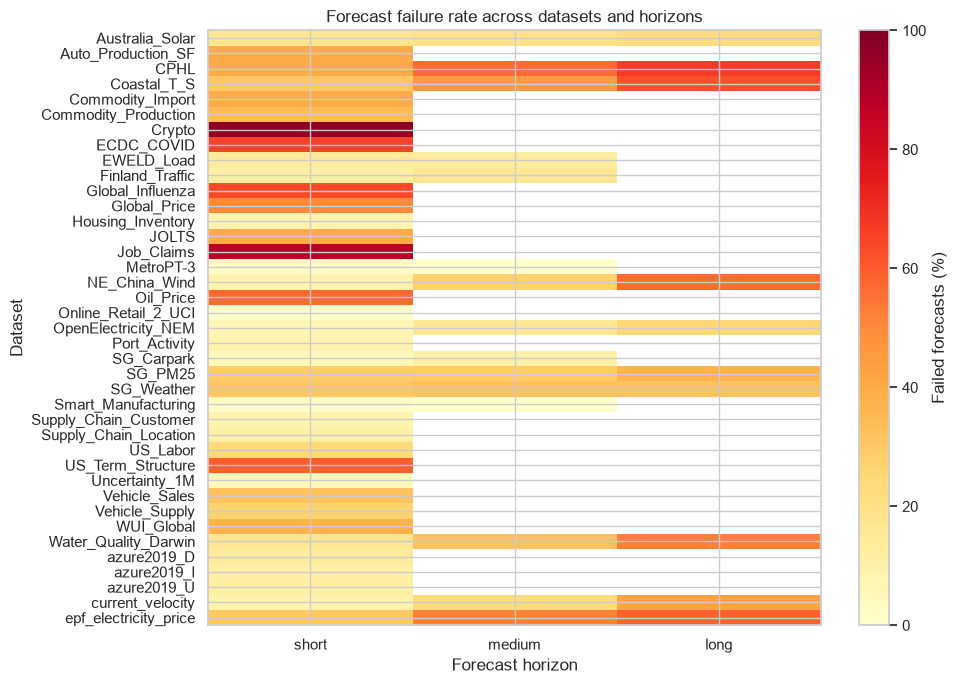

term,short,medium,long
dataset,,,
Australia_Solar,17.460317,19.047619,22.222222
Auto_Production_SF,40.000000,NaN,NaN
CPHL,39.527027,56.603774,66.666667
Coastal_T_S,30.602477,45.248538,62.222222
Commodity_Import,40.000000,NaN,NaN
Commodity_Production,34.375000,NaN,NaN
Crypto,97.222222,NaN,NaN
ECDC_COVID,65.137615,NaN,NaN
EWELD_Load,14.285714,13.571429,NaN


In [31]:
p2.plot_failure_heatmap(df_analysis, top_n=39)

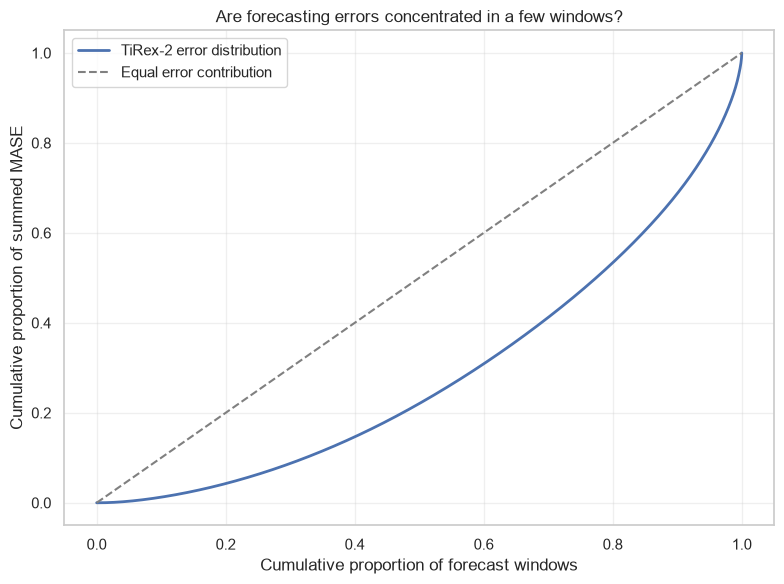

Worst 10% of windows contribute 31.26% of summed MASE


np.float64(31.256440331104617)

In [32]:
p2.plot_error_concentration(df_analysis)   #worst_pct=xx percentage

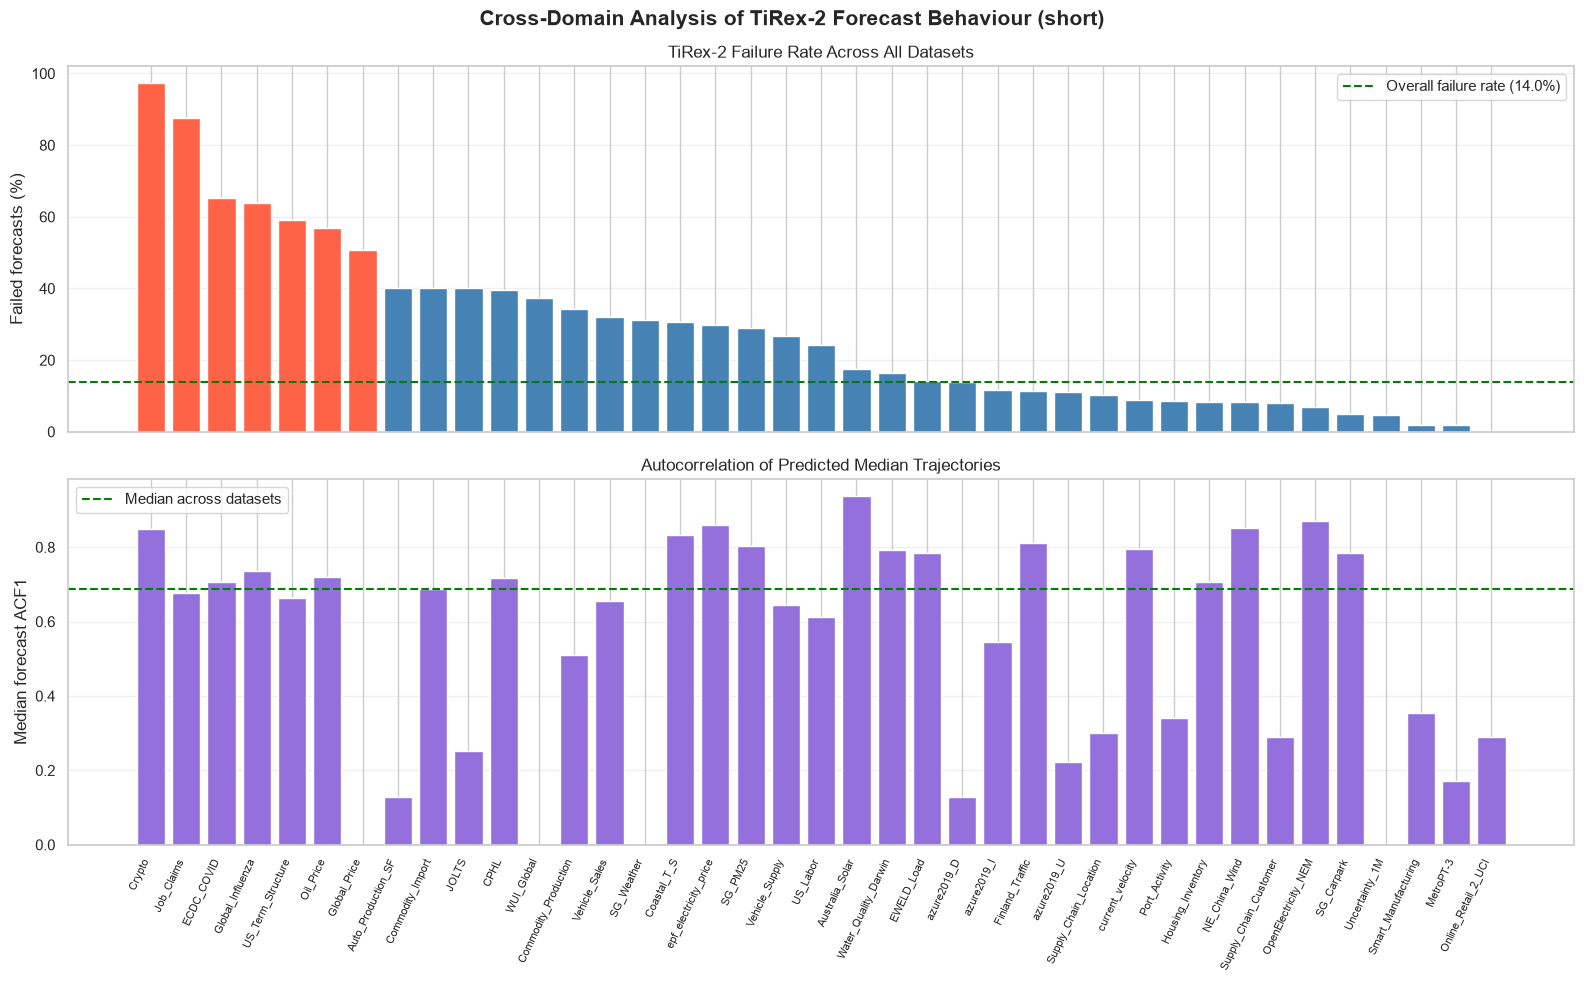

,failure_rate,median_MASE,forecast_acf1,n_windows
dataset,,,,
Crypto,97.222,4.076,0.849,36
Job_Claims,87.500,2.238,0.678,8
ECDC_COVID,65.138,1.432,0.707,109
Global_Influenza,63.750,1.469,0.737,237
US_Term_Structure,59.143,1.149,0.662,1400
Oil_Price,56.905,1.074,0.719,420
Global_Price,50.667,1.011,NaN,300
Auto_Production_SF,40.000,0.961,0.128,5
Commodity_Import,40.000,0.686,0.688,40


In [33]:
p2.plot_domain_behaviour(df_analysis, term="short")

Rows dropped (missing features): {'SG_Carpark': 8, 'Crypto': 4}


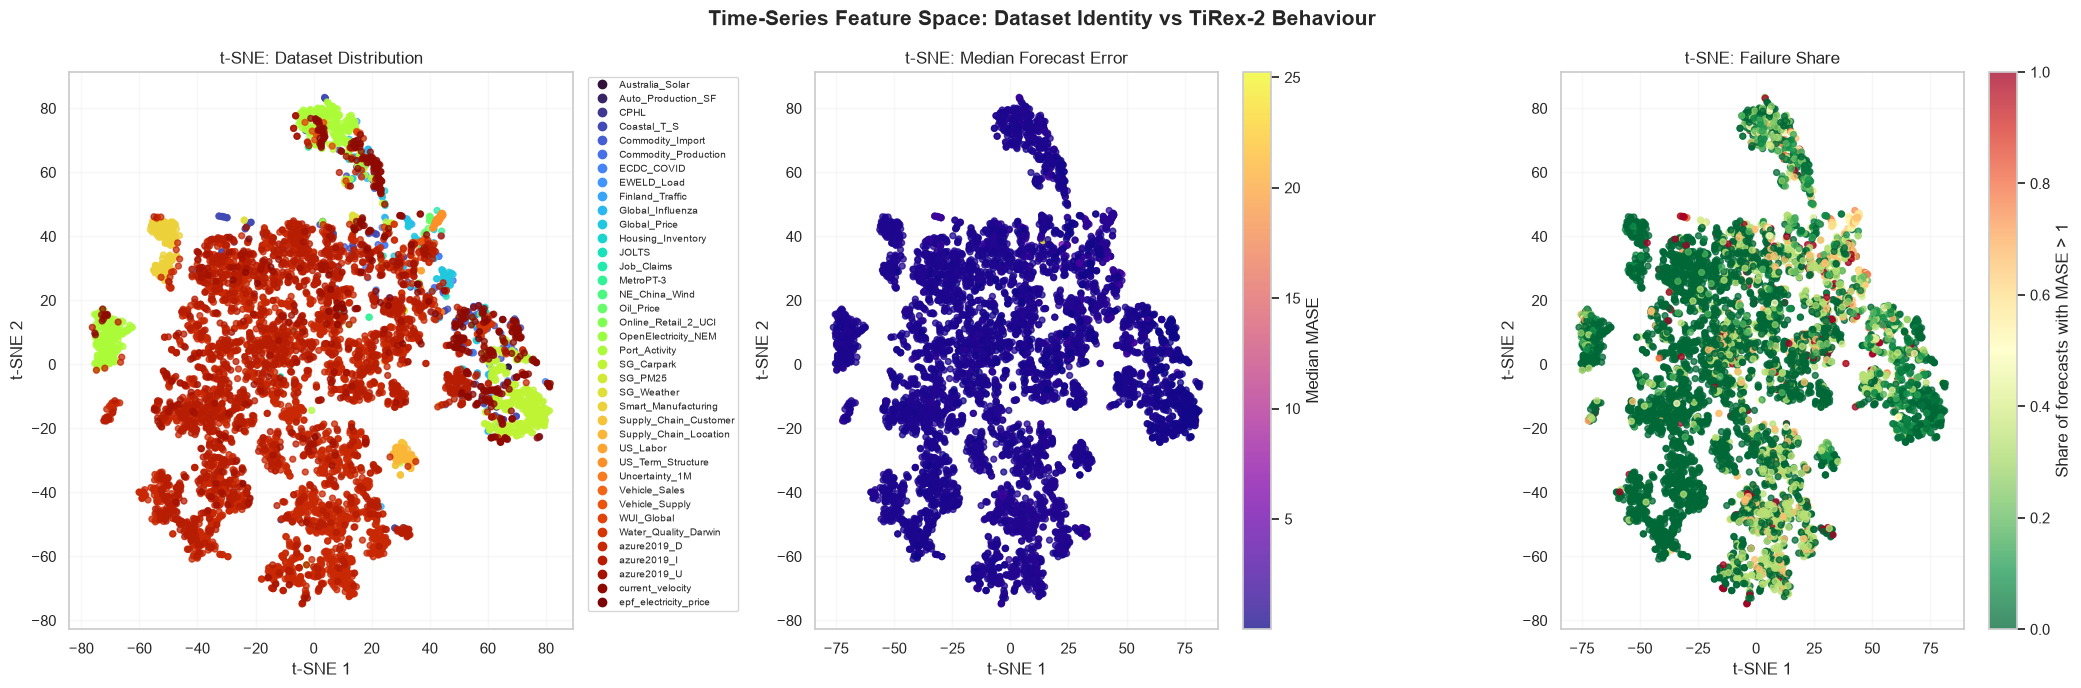

In [34]:
tsne_input = E.build_series_table(df_analysis, term="short")

tsne_result = E.embed(
    tsne_input,
    method="tsne",
    max_per_dataset=None,
    random_state=42
)

p2.plot_tsne_comparison(tsne_result)

Mean local failure similarity: 0.844


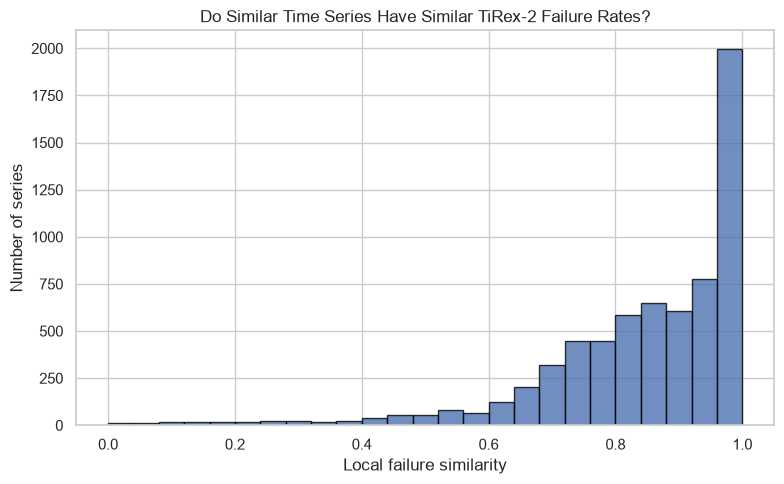

In [35]:
importlib.reload(p2)
tsne_result = p2.plot_local_failure_similarity(tsne_result)

In [36]:

import pandas as pd
import numpy as np
import plotly.express as px
import ipywidgets as widgets

from IPython.display import display, clear_output

# Work with existing dataframe
interactive_data = df_analysis.copy()

for col in ["dataset", "freq", "term"]:
    interactive_data[col] = interactive_data[col].astype(str)

ALL = "All"

datasets = [ALL] + sorted(interactive_data["dataset"].dropna().unique().tolist())
frequencies = [ALL] + sorted(interactive_data["freq"].dropna().unique().tolist())
terms = [ALL] + ["short", "medium", "long"]

features = [
    "feat_x_entropy",
    "feat_trend_strength",
    "feat_trend_stability",
    "feat_seasonal_strength",
    "feat_e_entropy",
    "width_norm",
    "trend_change_std",
    "acf1"
]

features = [f for f in features if f in interactive_data.columns]

metrics = ["MASE", "MAE", "RMSE", "CRPS"]
metrics = [m for m in metrics if m in interactive_data.columns]

# Full-width widget layout
full_width = widgets.Layout(width="100%")

dataset_dropdown = widgets.Dropdown(
    options=datasets,
    value=ALL,
    description="Dataset:",
    layout=full_width
)

freq_dropdown = widgets.Dropdown(
    options=frequencies,
    value=ALL,
    description="Frequency:",
    layout=full_width
)

term_dropdown = widgets.Dropdown(
    options=terms,
    value=ALL,
    description="Horizon:",
    layout=full_width
)

feature_dropdown = widgets.Dropdown(
    options=features,
    value="feat_x_entropy" if "feat_x_entropy" in features else features[0],
    description="X-axis:",
    layout=full_width
)

metric_dropdown = widgets.Dropdown(
    options=metrics,
    value="MASE",
    description="Y-axis:",
    layout=full_width
)

# Dashboard update function
def update_dashboard(dataset, freq, term, feature, metric):

    clear_output(wait=True)

    d = interactive_data.copy()

    if dataset != ALL:
        d = d[d["dataset"] == dataset]

    if freq != ALL:
        d = d[d["freq"] == freq]

    if term != ALL:
        d = d[d["term"] == term]

    d = d.dropna(subset=[feature, metric])

    if d.empty:
        print("No data available for these selections.")
        return

    d["Forecast behaviour"] = np.where(
        d["MASE"] > 1,
        "Worse than naive",
        "Better than naive"
    )

    print(f"Forecast windows: {len(d):,}")
    print(f"Median MASE: {d['MASE'].median():.3f}")
    print(f"Failure rate: {(d['MASE'] > 1).mean() * 100:.2f}%")

    # Sample data for faster rendering
    scatter_data = d.sample(
        n=min(8000, len(d)),
        random_state=42
    )

    # GRAPH 1: Full-width scatter plot
    fig1 = px.scatter(
        scatter_data,
        x=feature,
        y=metric,
        color="Forecast behaviour",
        hover_data=[
            "dataset",
            "freq",
            "term",
            "series_idx",
            "window_idx",
            "MASE"
        ],
        color_discrete_map={
            "Better than naive": "seagreen",
            "Worse than naive": "tomato"
        },
        opacity=0.65,
        title=f"{feature} vs {metric}"
    )

    fig1.update_layout(
        autosize=True,
        height=700,
        template="plotly_white",
        margin=dict(l=60, r=40, t=80, b=60),
        font=dict(size=13),
        legend=dict(
            orientation="h",
            yanchor="bottom",
            y=1.02,
            xanchor="right",
            x=1
        )
    )

    fig1.show(config={
        "responsive": True,
        "displayModeBar": True
    })

    # GRAPH 2: Full-width box plot
    fig2 = px.box(
        d,
        x="term",
        y=metric,
        color="freq",
        points=False,
        title=f"{metric} distribution across forecast horizons"
    )

    fig2.update_layout(
        autosize=True,
        height=650,
        template="plotly_white",
        margin=dict(l=60, r=40, t=80, b=60),
        font=dict(size=13),
        legend=dict(
            orientation="h",
            yanchor="bottom",
            y=1.02,
            xanchor="right",
            x=1
        )
    )

    fig2.show(config={
        "responsive": True,
        "displayModeBar": True
    })


# Full-width dashboard controls
controls = widgets.VBox(
    [
        widgets.HBox(
            [dataset_dropdown, freq_dropdown],
            layout=widgets.Layout(width="100%")
        ),
        widgets.HBox(
            [term_dropdown, feature_dropdown],
            layout=widgets.Layout(width="100%")
        ),
        metric_dropdown
    ],
    layout=widgets.Layout(
        width="100%",
        padding="10px"
    )
)

# Interactive dashboard
dashboard = widgets.interactive_output(
    update_dashboard,
    {
        "dataset": dataset_dropdown,
        "freq": freq_dropdown,
        "term": term_dropdown,
        "feature": feature_dropdown,
        "metric": metric_dropdown
    }
)

dashboard.layout = widgets.Layout(width="100%")

# Display everything
display(controls, dashboard)


Output(layout=Layout(width='100%'))

In [37]:
p2.create_tsne_dashboard(tsne_result)



Output()